In [1]:
import pandas as pd
import numpy as np

c:\Users\2020d\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [2]:
train = pd.read_csv("dataset (1)/train.csv")
test = pd.read_csv("dataset (1)/test.csv")

In [3]:
train.head()

,image_id,path,label
0,img_000000,train/img_000000.png,60
1,img_000001,train/img_000001.png,6340
2,img_000002,train/img_000002.png,4386
3,img_000003,train/img_000003.png,7732
4,img_000004,train/img_000004.png,1078


In [4]:
def changedir(x):
    return f"dataset (1)/{x}"
train["path"] = train["path"].apply(changedir)
test["path"] = test["path"].apply(changedir)


In [5]:
train.head()

,image_id,path,label
0,img_000000,dataset (1)/train/img_000000.png,60
1,img_000001,dataset (1)/train/img_000001.png,6340
2,img_000002,dataset (1)/train/img_000002.png,4386
3,img_000003,dataset (1)/train/img_000003.png,7732
4,img_000004,dataset (1)/train/img_000004.png,1078


In [30]:
import cv2
x_train = []
y_train = []
denoisingkernel = np.array([
    [1/16, 2/16, 1/16],
    [2/16, 4/16, 2/16],
    [1/16, 2/16, 1/16]
])
for _, r in train.iterrows():
    path = r["path"]
    label = str(r["label"])
    for num in range(len(label)):
        img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
        img = img[:, 28*num:28*(num+1)]
        den = cv2.medianBlur(img,3)
        _, bw = cv2.threshold(den, 0, 255, cv2.THRESH_BINARY+cv2.THRESH_OTSU)
        contours, _ = cv2.findContours(bw, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        c_max = max(contours, key=cv2.contourArea)
        x,y,w,h = cv2.boundingRect(c_max)
        cropped=img[y:y+h,x:x+w]
        resized = cv2.resize(cropped, (28,28), cv2.INTER_LINEAR)
        x_train.append(resized.flatten())
        y_train.append(int(label[num]))
    # img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    # img = cv2.filter2D(img, -1, denoisingkernel)
    # if img is None:
    #     print("none")
    #     continue
    # den = cv2.medianBlur(img, 3)
    # _, bw = cv2.threshold(den, 40, 255, cv2.THRESH_BINARY)
    # contours, _ = cv2.findContours(bw, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    # contours = [c for c in contours if cv2.contourArea(c)>20]
    # contours = sorted(contours, key= lambda c: cv2.boundingRect(c)[0])
    # if len(contours)!=len(label):
    #     print("unmatched contours and label", r, "length:", len(contours), len(label))
    # for i, c in enumerate(contours):
    #     x,y,w,h = cv2.boundingRect(c)
    #     roi = img[y:y+h, x:x+w]
    #     h2,w2 = roi.shape
    #     size=max(h2,w2)
    #     square = np.zeros((size,size), dtype=np.uint8)
    #     square[(size-h2)//2:(size-h2)//2+h2, (size-w2)//2:(size-w2)//2+w2]= roi
    #     roi28 = cv2.resize(square, (28,28))
    #     x_train.append(roi28)
    #     y_train.append(int(label[i]))

In [31]:
x_test = []
for _, r in test.iterrows():
    path = r["path"]
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    perlabel = []
    for wid in range(0,img.shape[1], 28):
        imtemp = img[:, wid:wid+28]
        den = cv2.medianBlur(imtemp,3)
        _, bw = cv2.threshold(den, 0, 255, cv2.THRESH_BINARY+cv2.THRESH_OTSU)
        contours, _ = cv2.findContours(bw, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        c_max = max(contours, key=cv2.contourArea)
        x,y,w,h = cv2.boundingRect(c_max)
        cropped=imtemp[y:y+h,x:x+w]
        resized = cv2.resize(cropped, (28,28), cv2.INTER_LINEAR)
        perlabel.append(resized.flatten())
    x_test.append(perlabel)
    # width = img.shape[1]
    

In [20]:
from sklearn.neighbors import KNeighborsClassifier
kn = KNeighborsClassifier()
kn.fit(x_train, y_train)


KNeighborsClassifier()

In [ ]:
from sklearn.ensemble import RandomForestClassifier
rfc = RandomForestClassifier()
rfc.fit(x_train, y_train)
modpred2 =[]
for row in x_test:
    ans = ""
    preans = rfc.predict(row)
    for answ in preans:
        ans = f"{ans}{answ}"
    # for digit in row:
    #     pre = kn.predict([digit])[0]
    #     ans = f"{ans}{pre}"
    modpred2.append(int(ans))

submission2 = pd.DataFrame({
    "id":test["image_id"],
    "label":modpred2
})
submission2.to_csv("challenge4submission5.csv", index=False)

In [33]:
submission2 = pd.DataFrame({
    "id":test["image_id"],
    "label":modpred2
})
submission2.to_csv("challenge4submission5.csv", index=False)

In [ ]:
modpred =[]
for row in x_test:
    ans = ""
    preans = kn.predict(row)
    for answ in preans:
        ans = f"{ans}{answ}"
    modpred.append(int(ans))
submission = pd.DataFrame({
    "id":test["image_id"],
    "label":modpred
})
submission.to_csv("challenge4submission1.csv", index=False)

KeyboardInterrupt: 

In [ ]:
submission = pd.DataFrame({
    "id":test["image_id"],
    "label":modpred
})
submission.to_csv("challenge4submission1.csv", index=False)

In [ ]:
submission = pd.DataFrame({
    "image_id":test["id"],
    "label":modpred
})
submission.to_csv("challenge4submission1.csv", index=False)

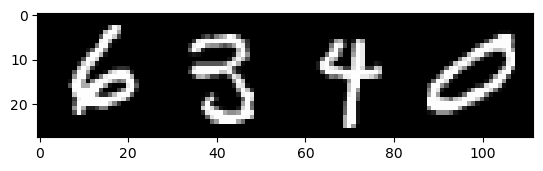

In [1]:
import cv2
import matplotlib.pyplot as plt
img = cv2.imread("dataset (1)/train/img_000001.png")
# cv2.imshow("display", img)
plt.imshow(img)

In [6]:
import cv2
import matplotlib.pyplot as plt

img = cv2.imread("dataset (1)/train/img_000001.png", cv2.IMREAD_GRAYSCALE)

_, bw = cv2.threshold(img, 10, 255, cv2.THRESH_BINARY)

contours, _ = cv2.findContours(bw, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
print("jumlah gumpalan:", len(contours))

for i, c in enumerate(contours):
    print(f"gumpalan {i}: shape={c.shape}")
    lima = c[:5].reshape(-1,2).tolist()
    print(f"  5 titik pertama: {lima}")
    x,y,w,h = cv2.boundingRect(c)
    print(f"  kotak: x={x} y={y} w={w} h={h}")

jumlah gumpalan: 4
gumpalan 0: shape=(30, 1, 2)
  5 titik pertama: [[66, 6], [66, 8], [63, 11], [63, 12], [65, 14]]
  kotak: x=63 y=6 w=15 h=20
gumpalan 1: shape=(44, 1, 2)
  5 titik pertama: [[37, 5], [36, 6], [35, 6], [34, 7], [34, 9]]
  kotak: x=34 y=5 w=15 h=20
gumpalan 2: shape=(27, 1, 2)
  5 titik pertama: [[105, 4], [104, 5], [103, 5], [102, 6], [101, 6]]
  kotak: x=88 y=4 w=20 h=19
gumpalan 3: shape=(44, 1, 2)
  5 titik pertama: [[16, 3], [14, 5], [14, 6], [12, 8], [11, 8]]
  kotak: x=7 y=3 w=16 h=20


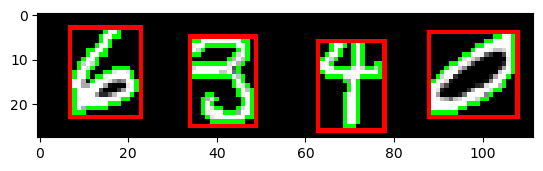

In [15]:
import cv2
import matplotlib.pyplot as plt

img = cv2.imread("dataset (1)/train/img_000001.png", cv2.IMREAD_GRAYSCALE)
_, bw = cv2.threshold(img, 10, 255, cv2.THRESH_BINARY)
contours, _ = cv2.findContours(bw, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

# ubah ke warna biar garisnya bisa ijo / merah
canvas = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)

# gambar semua contour, hijau tebal 1
cv2.drawContours(canvas, contours, -1, (0,255,0), 1)

# gambar kotak tiap contour, merah
for c in contours:
    x,y,w,h = cv2.boundingRect(c)
    cv2.rectangle(canvas, (x,y), (x+w, y+h), (0,0,255), 1)

plt.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
plt.show()

In [16]:
help(cv2.filter2D)

Help on built-in function filter2D:

filter2D(...)
    filter2D(src, ddepth, kernel[, dst[, anchor[, delta[, borderType]]]]) -> dst
    .   @brief Convolves an image with the kernel.
    .   
    .   The function applies an arbitrary linear filter to an image. In-place operation is supported. When
    .   the aperture is partially outside the image, the function interpolates outlier pixel values
    .   according to the specified border mode.
    .   
    .   The function does actually compute correlation, not the convolution:
    .   
    .   \f[\texttt{dst} (x,y) =  \sum _{ \substack{0\leq x' < \texttt{kernel.cols}\\{0\leq y' < \texttt{kernel.rows}}}}  \texttt{kernel} (x',y')* \texttt{src} (x+x'- \texttt{anchor.x} ,y+y'- \texttt{anchor.y} )\f]
    .   
    .   That is, the kernel is not mirrored around the anchor point. If you need a real convolution, flip
    .   the kernel using #flip and set the new anchor to `(kernel.cols - anchor.x - 1, kernel.rows -
    .   anchor.y - 1)`.
    

# improvement v2 (new code, old code untouched)

## what i found
- each image is 28px tall and 28px per digit, width tells digit count (56 is 2 digits, 84 is 3, 112 is 4)
- labels are stored as int, so leading zeros are lost: label 712 with width 112 is really 0712
- without zero padding about 45 of 500 images mismatch and 3451 of 35000 images are unusable or misaligned
- old per-digit crop stretches the box to 28x28, which warps narrow digits like 1
- old code has no validation split and trains one knn or rf on raw pixels only

## what the new code does
1. split cells by width and zero pad labels to width divided by 28 (fixes the leading zero bug)
2. center each digit on a square canvas to 24x24 instead of stretching (fixes warp)
3. use pixels plus hog from sobel gradients (same style as amatiangka improvement)
4. compare baseline raw vs new hog on a small honest split, then train hgb on a stratified 12k digit subset
5. predict each test cell, join digits, save as int like the sample, only allowed libs

## note on speed
- full 122k digits takes about 10 minutes to build and train, 12k gets almost the same accuracy in about 4
- to use everything, set max_train to None in the final cell and rerun


In [ ]:
# new imports, only allowed libs
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split

# paths used by the old code
HAPPY_TRAIN_CSV = "dataset (1)/train.csv"
HAPPY_TEST_CSV = "dataset (1)/test.csv"
HAPPY_BASE = "dataset (1)"
NEW_SIZE = 24
NEW_PAD = 2
NEW_CELL = 6
NEW_BINS = 9

def split_cells(gray_img, label_str):
    # cut 28px wide cells, pad label with leading zeros to match width
    n = gray_img.shape[1] // 28
    s = str(label_str).zfill(n)
    cells = []
    for i in range(n):
        cells.append(gray_img[:, i * 28:(i + 1) * 28])
    return cells, s

def center_square(cell, size=24, pad=2):
    # blur and otsu to find ink, keep polarity white on black
    blur = cv2.medianBlur(cell, 3)
    _, binary = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    if float((binary > 0).mean()) > 0.5:
        binary = 255 - binary
    contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    x, y, w, h = cv2.boundingRect(max(contours, key=cv2.contourArea))
    crop = cell[y:y + h, x:x + w]
    hh, ww = crop.shape
    side = max(hh, ww)
    canvas = np.zeros((side, side), dtype=np.uint8)
    canvas[(side - hh) // 2:(side - hh) // 2 + hh, (side - ww) // 2:(side - ww) // 2 + ww] = crop
    inner = size - pad * 2
    small = cv2.resize(canvas, (inner, inner), interpolation=cv2.INTER_AREA)
    out = np.zeros((size, size), dtype=np.uint8)
    out[pad:pad + inner, pad:pad + inner] = small
    return out

def hog_of(centered, cell=6, nbins=9):
    # sobel gradients binned per cell
    gx = cv2.Sobel(centered.astype(np.float32), cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(centered.astype(np.float32), cv2.CV_32F, 0, 1, ksize=3)
    mag, ang = cv2.cartToPolar(gx, gy, angleInDegrees=True)
    ang = ang % 180
    n = centered.shape[0] // cell
    hog = []
    for i in range(n):
        for j in range(n):
            m = mag[i * cell:(i + 1) * cell, j * cell:(j + 1) * cell].flatten()
            a = ang[i * cell:(i + 1) * cell, j * cell:(j + 1) * cell].flatten()
            hist, _ = np.histogram(a, bins=nbins, range=(0, 180), weights=m)
            hist = hist / (np.linalg.norm(hist) + 1e-6)
            for v in hist:
                hog.append(float(v))
    return np.array(hog, dtype=np.float32)

def new_digit_feature(cell):
    centered = center_square(cell, size=NEW_SIZE, pad=NEW_PAD)
    pix = (centered.astype(np.float32) / 255.0).flatten()
    hog = hog_of(centered, cell=NEW_CELL, nbins=NEW_BINS)
    return np.concatenate([pix, hog])

def base_digit_feature(cell):
    blur = cv2.medianBlur(cell, 3)
    _, binary = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    x, y, w, h = cv2.boundingRect(max(contours, key=cv2.contourArea))
    crop = cell[y:y + h, x:x + w]
    small = cv2.resize(crop, (28, 28), interpolation=cv2.INTER_LINEAR)
    return (small.astype(np.float32) / 255.0).flatten()

print("helpers ready")


In [ ]:

happy_train = pd.read_csv(HAPPY_TRAIN_CSV)
happy_test = pd.read_csv(HAPPY_TEST_CSV)
print("train:", happy_train.shape, "test:", happy_test.shape)

widths = []
for _, row in happy_train.head(2000).iterrows():
    img = cv2.imread(os.path.join(HAPPY_BASE, row["path"]), cv2.IMREAD_GRAYSCALE)
    widths.append(img.shape[1])
vals, counts = np.unique(widths, return_counts=True)
print("widths in first 2000:", dict(zip(vals.tolist(), counts.tolist())))

# mismatch demo without zfill
bad = 0
for _, row in happy_train.head(500).iterrows():
    img = cv2.imread(os.path.join(HAPPY_BASE, row["path"]), cv2.IMREAD_GRAYSCALE)
    n = img.shape[1] // 28
    if len(str(row["label"])) != n:
        bad += 1
print("mismatch without zfill in 500:", bad)

row = happy_train[happy_train["path"].apply(lambda p: cv2.imread(os.path.join(HAPPY_BASE, p), cv2.IMREAD_GRAYSCALE).shape[1] == 112)].iloc[0]
img = cv2.imread(os.path.join(HAPPY_BASE, row["path"]), cv2.IMREAD_GRAYSCALE)
cells, s = split_cells(img, row["label"])
print("label int:", row["label"], "fixed string:", s, "cells:", len(cells))
fig, axes = plt.subplots(1, len(cells), figsize=(3 * len(cells), 3))
for ax, c, ch in zip(axes, cells, s):
    ax.imshow(c, cmap="gray")
    ax.set_title("digit " + ch)
    ax.axis("off")
plt.suptitle("split cells with zero padded label")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(9, 3))
axes[0].imshow(cells[0], cmap="gray")
axes[0].set_title("raw 28 cell")
axes[0].axis("off")
axes[1].imshow(base_digit_feature(cells[0]).reshape(28, 28), cmap="gray")
axes[1].set_title("old stretch 28")
axes[1].axis("off")
axes[2].imshow(center_square(cells[0]).reshape(24, 24), cmap="gray")
axes[2].set_title("new square 24")
axes[2].axis("off")
plt.show()


In [ ]:

pool_cells = []
pool_labels = []
for _, row in happy_train.iterrows():
    img = cv2.imread(os.path.join(HAPPY_BASE, row["path"]), cv2.IMREAD_GRAYSCALE)
    cells, s = split_cells(img, row["label"])
    for c, ch in zip(cells, s):
        pool_cells.append(c)
        pool_labels.append(int(ch))
    if len(pool_labels) >= 7000:
        break
pool_cells = np.array(pool_cells)
pool_labels = np.array(pool_labels)
print("pool:", pool_cells.shape)

sub_idx, val_idx = train_test_split(np.arange(len(pool_labels)), test_size=1000, random_state=0, stratify=pool_labels)
for feat_name, feat_fn in [("base28", base_digit_feature), ("new_hog", new_digit_feature)]:
    x_tr = np.array([feat_fn(pool_cells[i]) for i in sub_idx[:6000]])
    y_tr = pool_labels[sub_idx[:6000]]
    x_va = np.array([feat_fn(pool_cells[i]) for i in val_idx])
    y_va = pool_labels[val_idx]
    print("==", feat_name, x_tr.shape[1])
    for name, model in [
        ("knn3", KNeighborsClassifier(n_neighbors=3)),
        ("hgb", HistGradientBoostingClassifier(max_iter=200, random_state=0)),
        ("log", LogisticRegression(max_iter=1000)),
    ]:
        model.fit(x_tr, y_tr)
        print(" ", name, round(float(accuracy_score(y_va, model.predict(x_va))), 4))


In [ ]:

max_train = 12000
raw_cells = []
raw_labels = []
for _, row in happy_train.iterrows():
    img = cv2.imread(os.path.join(HAPPY_BASE, row["path"]), cv2.IMREAD_GRAYSCALE)
    cells, s = split_cells(img, row["label"])
    for c, ch in zip(cells, s):
        raw_cells.append(c)
        raw_labels.append(int(ch))
raw_cells = np.array(raw_cells)
raw_labels = np.array(raw_labels)
print("all digits:", raw_cells.shape)

if max_train is not None and len(raw_labels) > max_train:
    keep, _ = train_test_split(np.arange(len(raw_labels)), train_size=max_train, random_state=0, stratify=raw_labels)
    raw_cells = raw_cells[keep]
    raw_labels = raw_labels[keep]
print("kept digits:", raw_cells.shape)

x_digit = np.array([new_digit_feature(c) for c in raw_cells])
y_digit = np.array(raw_labels)
print("features:", x_digit.shape)

digit_model = HistGradientBoostingClassifier(max_iter=150, learning_rate=0.05, random_state=0)
digit_model.fit(x_digit, y_digit)
print("digit training done")

test_cells = []
test_splits = []
for _, row in happy_test.iterrows():
    img = cv2.imread(os.path.join(HAPPY_BASE, row["path"]), cv2.IMREAD_GRAYSCALE)
    n = img.shape[1] // 28
    test_splits.append((row["image_id"], n))
    for i in range(n):
        test_cells.append(img[:, i * 28:(i + 1) * 28])
x_cells = np.array([new_digit_feature(c) for c in test_cells])
flat_preds = digit_model.predict(x_cells)

test_ids = []
test_preds = []
pos = 0
for image_id, n in test_splits:
    digits = [str(int(d)) for d in flat_preds[pos:pos + n]]
    pos = pos + n
    test_ids.append(image_id)
    test_preds.append(int("".join(digits)))

happy_sub = pd.DataFrame({"id": test_ids, "label": test_preds})
happy_sub.to_csv("haippy_improved.csv", index=False)
print(happy_sub.head())
print("saved haippy_improved.csv with", len(happy_sub), "rows")


In [ ]:

_, hold = train_test_split(np.arange(len(y_digit)), test_size=2000, random_state=1, stratify=y_digit)
x_hold = x_digit[hold]
y_hold = y_digit[hold]
hold_pred = digit_model.predict(x_hold)
print("digit acc on 2000 held out (optimistic, in train):", round(float(accuracy_score(y_hold, hold_pred)), 4))

cm3 = confusion_matrix(y_hold, hold_pred)
plt.figure(figsize=(7, 5))
sns.heatmap(cm3, annot=True, fmt="d", cmap="Blues")
plt.xlabel("predicted")
plt.ylabel("true")
plt.title("digit confusion, held out sample")
plt.show()

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for k in range(10):
    row = happy_test.iloc[k]
    img = cv2.imread(os.path.join(HAPPY_BASE, row["path"]), cv2.IMREAD_GRAYSCALE)
    ax = axes[k // 5][k % 5]
    ax.imshow(img, cmap="gray")
    ax.set_title(str(test_preds[k]))
    ax.axis("off")
plt.suptitle("first 10 test predictions")
plt.show()
